# Comparing the commutes of New York and Houston

05.3 and 05.3.1 routed the LODES commutes between the kept tracts of each area with cafein, by car,
bicycle, e-bike and transit, and saved one table per area with every pair of tracts, its workers and
its travel times. This notebook puts the two tables side by side. Two choices differ between the
areas and matter when reading the numbers: New York keeps the tracts with at most 10 km2 of land and
Houston those with at most 20 km2, and the transit departure is Tuesday 2026-10-20 in New York and
Tuesday 2026-11-10 in Houston, both at 08:30. Everything else is routed the same way, including the
120-minute cap on street routes, so a ride longer than that counts as not reached.

| Step | What we do |
|---|---|
| 1. The two tables | The OD tables of both areas loaded, the worker-weighted summary of each mode side by side, and the share of commuters whose commute fits in a given number of minutes, one panel per area |
| 2. Maps | The median commute of the residents of each home tract, one zoomable map per area on a street basemap, the mode chosen in the layer control, the same colour scale everywhere |


In [1]:
from pathlib import Path

import branca.colormap as cm
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

## 1. The two tables

Each area has one table with a row per pair of tracts that has a flow between routing points, its
workers, the straight-line distance between the two points and the travel time of each mode in
minutes, missing when the mode does not reach the pair. The summary weights every figure by the
workers of the pair, so it describes commuters rather than tract pairs. The share reached is the
share of workers whose commute has a time; for the street modes it is the share within the
120-minute cap, for transit the share with an itinerary at the departure.

In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
AREAS = {
    "New York": {"folder": RESULTS / "new-york", "tract_rule_km2": 10, "departure": "2026-10-20 08:30", "metric_crs": "EPSG:32618", "zoom": 9},
    "Houston": {"folder": RESULTS / "houston", "tract_rule_km2": 20, "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32615", "zoom": 10},
    "Chicago": {"folder": RESULTS / "chicago", "tract_rule_km2": 20, "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32616", "zoom": 9},
    "Seattle": {"folder": RESULTS / "seattle", "tract_rule_km2": 20, "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32610", "zoom": 10},
    "Phoenix": {"folder": RESULTS / "phoenix", "tract_rule_km2": 20, "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32612", "zoom": 10},
}
# The modes compared, with the label used in tables and maps. Free-flow car is left out.
MODES = {"car": "car, rush hour", "bicycle": "bicycle", "e_bike": "e-bike", "transit": "transit"}

od = {}
tracts = {}
medians = {}
for area, spec in AREAS.items():
    od[area] = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet")
    tracts[area] = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")
    medians[area] = pd.read_parquet(spec["folder"] / "matrices" / f"median-minutes-by-home-tract-{YEAR}.parquet")
    print(f"{area}: {len(od[area]):,} tract pairs, {od[area]['workers'].sum():,} workers, {len(tracts[area]):,} tracts kept "
          f"(at most {spec['tract_rule_km2']} km2), transit at {spec['departure']}")

New York: 2,408,240 tract pairs, 6,708,932 workers, 4,589 tracts kept (at most 10 km2), transit at 2026-10-20 08:30
Houston: 608,199 tract pairs, 2,114,670 workers, 1,447 tracts kept (at most 20 km2), transit at 2026-11-10 08:30
Chicago: 933,646 tract pairs, 3,423,828 workers, 2,153 tracts kept (at most 20 km2), transit at 2026-11-10 08:30
Seattle: 253,835 tract pairs, 1,531,980 workers, 791 tracts kept (at most 20 km2), transit at 2026-11-10 08:30
Phoenix: 386,194 tract pairs, 1,748,052 workers, 1,008 tracts kept (at most 20 km2), transit at 2026-11-10 08:30


In [3]:
def weighted_percentile(values, weights, percentile):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, percentile / 100)]


rows = []
for area, table in od.items():
    for mode, label in MODES.items():
        reached = table[f"{mode}_min"].notna()
        minutes = table.loc[reached, f"{mode}_min"].to_numpy()
        weights = table.loc[reached, "workers"].to_numpy()
        rows.append({
            "mode": label, "area": area,
            "share of workers reached": weights.sum() / table["workers"].sum(),
            "median minutes": weighted_percentile(minutes, weights, 50),
            "mean minutes": np.average(minutes, weights=weights),
            "p90 minutes": weighted_percentile(minutes, weights, 90),
        })
summary = pd.DataFrame(rows).set_index(["mode", "area"]).unstack("area")
summary = summary.reindex(list(MODES.values())).reindex(columns=list(AREAS), level="area")
print("commutes between the kept tracts, worker-weighted, over the pairs each mode reaches:")
summary.round(2)

commutes between the kept tracts, worker-weighted, over the pairs each mode reaches:


share of workers reached                                  \
area                           New York Houston Chicago Seattle Phoenix   
mode                                                                      
car, rush hour                     0.99    1.00    0.99    0.99    1.00   
bicycle                            0.75    0.65    0.71    0.76    0.68   
e-bike                             0.79    0.71    0.76    0.81    0.74   
transit                            0.91    0.32    0.67    0.85    0.60   

               median minutes                                 mean minutes  \
area                 New York Houston Chicago Seattle Phoenix     New York   
mode                                                                         
car, rush hour          31.02   38.45   38.88   34.57   37.70        35.11   
bicycle                 42.00   59.43   50.13   53.42   61.47        47.03   
e-bike                  39.10   57.12   47.22   50.17   58.42        44.96   
transit                 65.87   75.78   77.13   77.68   94.40        84.29   

                                               p90 minutes                  \
area           Houston Chicago Seattle Phoenix    New York Houston Chicago   
mode                                                                         
car, rush hour   40.30   41.33   37.22   39.17       65.47   65.97   72.98   
bicycle          60.14   52.91   55.29   61.47       95.28  106.05   99.87   
e-bike           58.44   50.81   52.62   59.21       93.50  104.45   98.30   
transit          81.82   95.64   86.38  106.14      155.40  131.73  187.23   

                                
area           Seattle Phoenix  
mode                            
car, rush hour   62.92   63.25  
bicycle         101.23  105.73  
e-bike           98.37  103.75  
transit         146.10  167.83

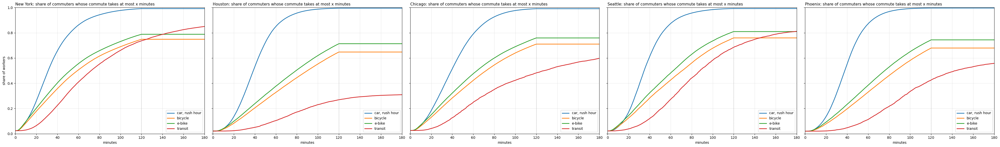

In [4]:
# Share of all commuters whose commute takes at most x minutes, by mode. The height a curve
# reaches at the right is the share of workers reached; the street modes stop at the 120-minute
# cap, transit continues beyond the axis.
axis_minutes = np.arange(0, 181)
figure, axes = plt.subplots(ncols=len(AREAS), figsize=(8 * len(AREAS), 6), sharey=True)
for axis, (area, table) in zip(axes, od.items()):
    total = table["workers"].sum()
    for mode, label in MODES.items():
        reached = table[f"{mode}_min"].notna()
        order = np.argsort(table.loc[reached, f"{mode}_min"].to_numpy())
        minutes = table.loc[reached, f"{mode}_min"].to_numpy()[order]
        cumulative = np.cumsum(table.loc[reached, "workers"].to_numpy()[order]) / total
        position = np.searchsorted(minutes, axis_minutes, side="right")
        share = np.where(position > 0, cumulative[np.maximum(position - 1, 0)], 0.0)
        axis.plot(axis_minutes, share, label=label, linewidth=2)
    axis.axvline(120, color="#999999", linestyle=":", linewidth=1)
    axis.set_title(f"{area}: share of commuters whose commute takes at most x minutes", loc="left", fontsize=11)
    axis.set_xlabel("minutes")
    axis.set_xlim(0, 180)
    axis.set_ylim(0, 1)
    axis.grid(alpha=0.3)
    axis.legend(loc="lower right")
axes[0].set_ylabel("share of workers")
figure.tight_layout()

## 2. Maps

One map per area, each on its own so that it can be read at full size: the worker-weighted median
commute of the residents of each home tract, from the per-tract tables of 05.3 and 05.3.1. The
basemap is Esri World Street Map, which serves tiles without a key to embedded viewers such as the
notebook pane; openstreetmap.org blocks those viewers and CARTO asks for a key. The four modes are
separate layers chosen one at a time in the control at the top right, all on the same colour scale,
so the same colour means the same minutes in both areas and in every mode; the legend is plain
HTML at the bottom left, since the notebook pane does not always load the script branca's legend
needs, and that failure also removed the layer control. Tracts in grey have no resident reaching
work by that mode. The tooltip gives the tract, its county, its resident workers
and the four medians. Polygons are simplified to 50 m for the browser; each map is also saved as an
HTML file in `figures/`.

In [5]:
BINS = [0, 15, 30, 45, 60, 90, 120, 180]
COLOURS = ["#ffffcc", "#c7e9b4", "#7fcdbb", "#41b6c4", "#1d91c0", "#225ea8", "#0c2c84"]
colormap = cm.StepColormap(COLOURS, index=BINS, vmin=BINS[0], vmax=BINS[-1])
# The legend as plain HTML inside the map, without the d3 script branca's legend loads from a CDN.
LEGEND = ("<div style=\"position: fixed; bottom: 24px; left: 12px; z-index: 1000; background: white; padding: 8px 10px; "
          "border: 1px solid #999999; border-radius: 4px; font: 12px/1.5 sans-serif;\">"
          "<b>median commute of the tract's resident workers (minutes)</b><br>"
          + "".join(f"<span style=\"display: inline-block; width: 14px; height: 14px; background: {colour}; "
                    f"border: 1px solid #777777; vertical-align: middle; margin-right: 4px;\"></span>{low} to {high}<br>"
                    for colour, low, high in zip(COLOURS, BINS[:-1], BINS[1:]))
          + "<span style=\"display: inline-block; width: 14px; height: 14px; background: #d9d9d9; border: 1px solid #777777; "
          "vertical-align: middle; margin-right: 4px;\"></span>no resident reaches work</div>")
TILES = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"
TILES_ATTRIBUTION = "Tiles: Esri, HERE, Garmin, OpenStreetMap contributors"


def colour(minutes):
    if minutes is None or np.isnan(minutes):
        return "#d9d9d9"
    return colormap(min(minutes, BINS[-1] - 0.01))


def commute_map(area):
    spec = AREAS[area]
    columns = {f"{mode}_median_min": f"median minutes by {label}" for mode, label in MODES.items()}
    shown = tracts[area][["tract", "NAMELSADCO", "geometry"]].merge(medians[area], on="tract", how="inner")
    shown = shown.to_crs(spec["metric_crs"])
    shown["geometry"] = shown.geometry.simplify(50)
    shown = shown.to_crs("EPSG:4326")
    shown["geometry"] = shapely.set_precision(shown.geometry, 1e-4)
    shown["residents"] = shown["residents"].round(0)
    shown[list(columns)] = shown[list(columns)].round(0)
    fields = ["tract", "NAMELSADCO", "residents"] + list(columns)
    aliases = ["tract", "county", "resident workers"] + list(columns.values())

    centre = [shown.geometry.union_all().centroid.y, shown.geometry.union_all().centroid.x]
    zoomable = folium.Map(location=centre, zoom_start=spec["zoom"], tiles=None, height=800)
    folium.TileLayer(tiles=TILES, attr=TILES_ATTRIBUTION, name="Esri World Street Map", control=False).add_to(zoomable)
    for mode, label in MODES.items():
        column = f"{mode}_median_min"
        layer = folium.FeatureGroup(name=f"median commute by {label}", overlay=False, show=(mode == "car"))
        folium.GeoJson(
            shown.to_json(),
            style_function=lambda feature, column=column: {"fillColor": colour(feature["properties"][column]), "fillOpacity": 0.65, "color": "#555555", "weight": 0.3},
            tooltip=folium.GeoJsonTooltip(fields=fields, aliases=aliases),
        ).add_to(layer)
        layer.add_to(zoomable)
    folium.LayerControl(collapsed=False).add_to(zoomable)
    zoomable.get_root().html.add_child(folium.Element(LEGEND))
    zoomable.save(FIGURES / f"05.4-median-commute-{area.lower().replace(' ', '-')}.html")
    return zoomable


commute_map("New York")

In [6]:
commute_map("Houston")
commute_map("Chicago")
commute_map("Seattle")
commute_map("Phoenix")